In [13]:

from pathlib import Path
import json
import pandas as pd

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook13_privacy_leakage_analysis"
OUT_DIR.mkdir(parents=True, exist_ok=True)

required_files = {
    "Baseline checkpoint":
        PROJECT / "UBIRIS_V2_baseline_resnet18_best.pth",
    "Augmented recognition checkpoint":
        PROJECT / "notebook10_augmented_recognition/UBIRIS_V2_augmented_resnet18_best.pth",
    "Membership attack summary":
        PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_attack_summary.json",
    "Membership group scores":
        PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_group_scores.csv",
    "Membership attack summary CSV":
        PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_attack_summary.csv",
    "GAN checkpoint":
        PROJECT / "notebook07_gan_augmentation/UBIRIS_V2_GAN_checkpoint.pth",
    "Diffusion checkpoint":
        PROJECT / "notebook06_diffusion_training/UBIRIS_V2_ddpm_checkpoint.pth",
}

print("NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS")
print("=" * 65)

for name, path in required_files.items():
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status:8} {name}")
    if path.is_file():
        print(f"         Size: {path.stat().st_size:,} bytes")

attack_json = required_files["Membership attack summary"]
if attack_json.is_file():
    with open(attack_json, encoding="utf-8") as f:
        data = json.load(f)
    print("\nSaved membership attack results:")
    print(json.dumps(data, indent=2)[:7000])

attack_csv = required_files["Membership attack summary CSV"]
if attack_csv.is_file():
    df = pd.read_csv(attack_csv)
    print("\nMembership attack metrics:")
    print(df.to_string(index=False))

print("\nSetup inspection complete.")


NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS
FOUND    Baseline checkpoint
         Size: 45,297,675 bytes
FOUND    Augmented recognition checkpoint
         Size: 45,297,291 bytes
FOUND    Membership attack summary
         Size: 2,701 bytes
FOUND    Membership group scores
         Size: 524 bytes
FOUND    Membership attack summary CSV
         Size: 1,057 bytes
FOUND    GAN checkpoint
         Size: 37,113,173 bytes
FOUND    Diffusion checkpoint
         Size: 15,533,419 bytes

Saved membership attack results:
{
  "experiment": "Loss-based membership inference",
  "dataset": "UBIRIS V2",
  "score_definition": "Negative true-label cross-entropy loss; higher means more member-like",
  "member_source": "Original training split",
  "nonmember_source": "Original test split",
  "train_images_evaluated": 4243,
  "test_images_evaluated": 778,
  "num_classes": 260,
  "runtime_seconds": 11.61,
  "model_results": [
    {
      "model": "baseline",
      "members": 4243,
      "nonmembers": 778,
     

NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS


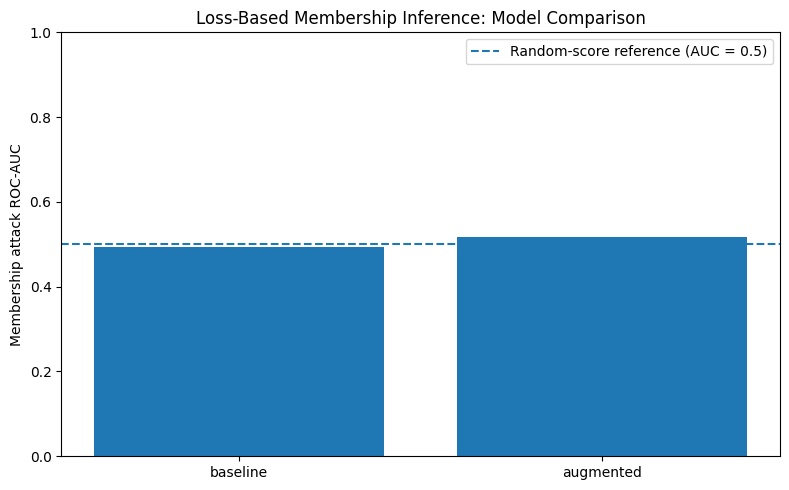

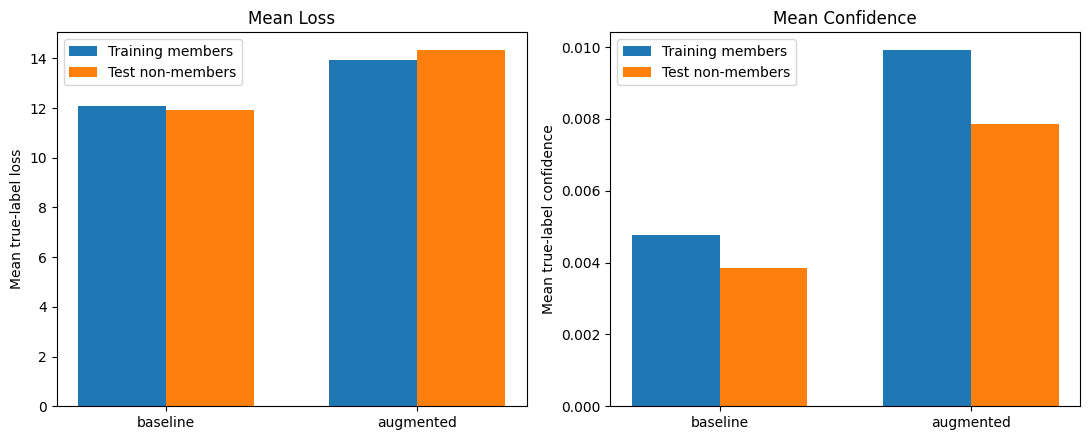


OUTPUT VERIFICATION
OK       UBIRIS_V2_privacy_leakage_metrics.csv
OK       UBIRIS_V2_privacy_attack_auc.png
OK       UBIRIS_V2_member_nonmember_comparison.png
OK       Notebook13_Conclusion.md
OK       Notebook13_Analysis_Summary.json

FINAL RESULTS
    model  attack_roc_auc  auc_distance_from_random  loss_gap_member_minus_nonmember  confidence_gap_member_minus_nonmember
 baseline        0.492923                  0.007077                         0.126577                               0.000933
augmented        0.516817                  0.016817                        -0.401544                               0.002067

Runtime: 0.71 seconds
ZIP: /kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook13_Results.zip
ZIP integrity: PASSED


/kaggle/working/ubiris_v2_project/notebook13_privacy_leakage_analysis/Notebook13_Conclusion.md

/kaggle/working/ubiris_v2_project/UBIRIS_V2_Notebook13_Results.zip

In [14]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from IPython.display import FileLink, display
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS
# ============================================================
PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT = PROJECT / "notebook13_privacy_leakage_analysis"
OUT.mkdir(parents=True, exist_ok=True)

ATTACK_JSON = PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_attack_summary.json"
ATTACK_CSV = PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_attack_summary.csv"
SCORES_CSV = PROJECT / "notebook12_membership_inference/UBIRIS_V2_membership_group_scores.csv"

start = time.time()
print("=" * 68)
print("NOTEBOOK 13 — PRIVACY LEAKAGE ANALYSIS")
print("=" * 68)

# 1. Validate and load existing attack results
for p in [ATTACK_JSON, ATTACK_CSV, SCORES_CSV]:
    if not p.is_file():
        raise FileNotFoundError(f"Required Notebook 12 output missing: {p}")

with open(ATTACK_JSON, encoding="utf-8") as f:
    attack_data = json.load(f)

results = pd.DataFrame(attack_data["model_results"])
required_cols = {"model", "attack_roc_auc", "member_mean_loss",
                 "nonmember_mean_loss", "member_mean_confidence",
                 "nonmember_mean_confidence"}
missing = required_cols - set(results.columns)
if missing:
    raise ValueError(f"Missing expected membership metrics: {missing}")

results["auc_distance_from_random"] = (results["attack_roc_auc"] - 0.5).abs()
results["loss_gap_member_minus_nonmember"] = (
    results["member_mean_loss"] - results["nonmember_mean_loss"]
)
results["confidence_gap_member_minus_nonmember"] = (
    results["member_mean_confidence"] - results["nonmember_mean_confidence"]
)
results["interpretation"] = results["attack_roc_auc"].apply(
    lambda x: "Near-random score separation in this experiment"
    if abs(x - 0.5) < 0.05 else
    ("Above-random score separation; further validation required"
     if x > 0.5 else
     "Below-random score orientation; inspect score definition and setup")
)

results.to_csv(OUT / "UBIRIS_V2_privacy_leakage_metrics.csv", index=False)

# 2. Plot AUC against the random-attack reference
plt.figure(figsize=(8, 5))
plt.bar(results["model"], results["attack_roc_auc"])
plt.axhline(0.5, linestyle="--", label="Random-score reference (AUC = 0.5)")
plt.ylim(0, 1)
plt.ylabel("Membership attack ROC-AUC")
plt.title("Loss-Based Membership Inference: Model Comparison")
plt.legend()
plt.tight_layout()
plt.savefig(OUT / "UBIRIS_V2_privacy_attack_auc.png", dpi=160)
plt.show()
plt.close()

# 3. Plot mean loss and confidence, keeping their scales separate
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

x = np.arange(len(results))
width = 0.35
axes[0].bar(x - width/2, results["member_mean_loss"], width,
            label="Training members")
axes[0].bar(x + width/2, results["nonmember_mean_loss"], width,
            label="Test non-members")
axes[0].set_xticks(x, results["model"])
axes[0].set_ylabel("Mean true-label loss")
axes[0].set_title("Mean Loss")
axes[0].legend()

axes[1].bar(x - width/2, results["member_mean_confidence"], width,
            label="Training members")
axes[1].bar(x + width/2, results["nonmember_mean_confidence"], width,
            label="Test non-members")
axes[1].set_xticks(x, results["model"])
axes[1].set_ylabel("Mean true-label confidence")
axes[1].set_title("Mean Confidence")
axes[1].legend()

fig.tight_layout()
fig.savefig(OUT / "UBIRIS_V2_member_nonmember_comparison.png", dpi=160)
plt.show()
plt.close(fig)

# 4. Write a transparent conclusion
auc_by_model = dict(zip(results["model"], results["attack_roc_auc"]))
baseline_auc = auc_by_model.get("baseline", float("nan"))
augmented_auc = auc_by_model.get("augmented", float("nan"))

conclusion = f"""# Notebook 13 — Privacy Leakage Analysis

## Objective
Analyze the existing loss-based membership-inference results for the UBIRIS V2
baseline and augmented recognition models.

## Results
| Model | Attack ROC-AUC | Mean member loss | Mean non-member loss |
|---|---:|---:|---:|
"""
for _, r in results.iterrows():
    conclusion += (
        f"| {r['model']} | {r['attack_roc_auc']:.4f} | "
        f"{r['member_mean_loss']:.4f} | {r['nonmember_mean_loss']:.4f} |\\n"
    )

conclusion += f"""
## Interpretation
- Baseline membership attack ROC-AUC: {baseline_auc:.4f}.
- Augmented-model membership attack ROC-AUC: {augmented_auc:.4f}.
- An ROC-AUC near 0.5 indicates little member/non-member separation by this
  particular score under this experiment.
- The augmented result is slightly above 0.5, but this alone does not establish
  a confirmed privacy breach or meaningful real-world attack capability.
- The threshold-based accuracy, precision, recall, and F1 from Notebook 12
  used a threshold selected on the evaluated groups. They are exploratory and
  should not be treated as independent generalization estimates.

## Important limitations
1. The split is image-level, not subject-disjoint; identities may occur in both
   groups.
2. Membership scores are based on negative true-label cross-entropy loss.
3. This is one attack method, not a comprehensive privacy audit.
4. The very low reported recognition accuracies in Notebook 12 warrant checking
   checkpoint loading, class-label mapping, preprocessing, and test split
   consistency before drawing wider conclusions.
5. This experiment does not test identity reconstruction, attribute inference,
   model inversion, or leakage from individual GAN/diffusion samples.
6. These results do not prove that either model is private or non-private.

## Conclusion
The tested loss-based attack showed near-random membership separation for the
baseline model and only a small above-random AUC for the augmented model.
The result is limited to the present evaluation setup. Stronger claims require
a carefully held-out attack evaluation, subject-disjoint splits where suitable,
validated model evaluation, and additional attack methods.

Notebook 12's original results are retained as the source of these metrics.
"""

(OUT / "Notebook13_Conclusion.md").write_text(conclusion, encoding="utf-8")
(OUT / "Notebook13_Analysis_Summary.json").write_text(
    json.dumps({
        "notebook": 13,
        "title": "Privacy Leakage Analysis",
        "dataset": "UBIRIS V2",
        "attack": "Loss-based membership inference",
        "model_results": results.to_dict(orient="records"),
        "limitations": attack_data.get("limitations", []),
        "interpretation": (
            "Near-random membership separation for this particular attack; "
            "not proof of privacy."
        )
    }, indent=2, default=str),
    encoding="utf-8"
)

# 5. Verify outputs and package Notebook 13 results
expected = [
    OUT / "UBIRIS_V2_privacy_leakage_metrics.csv",
    OUT / "UBIRIS_V2_privacy_attack_auc.png",
    OUT / "UBIRIS_V2_member_nonmember_comparison.png",
    OUT / "Notebook13_Conclusion.md",
    OUT / "Notebook13_Analysis_Summary.json",
]
print("\nOUTPUT VERIFICATION")
for p in expected:
    print(("OK      " if p.is_file() and p.stat().st_size > 0 else "MISSING "), p.name)

zip_path = PROJECT / "UBIRIS_V2_Notebook13_Results.zip"
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for p in expected:
        if p.is_file():
            zf.write(p, arcname=p.relative_to(PROJECT))

with ZipFile(zip_path, "r") as zf:
    bad = zf.testzip()
    if bad:
        raise RuntimeError(f"ZIP integrity check failed: {bad}")

print("\nFINAL RESULTS")
print(results[[
    "model", "attack_roc_auc", "auc_distance_from_random",
    "loss_gap_member_minus_nonmember",
    "confidence_gap_member_minus_nonmember"
]].to_string(index=False))
print(f"\nRuntime: {time.time() - start:.2f} seconds")
print("ZIP:", zip_path)
print("ZIP integrity: PASSED")

display(FileLink(str(OUT / "Notebook13_Conclusion.md")))
display(FileLink(str(zip_path)))
